In [53]:

# STEP 1: Install and import libraries

%pip -q install nltk gensim scikit-learn

import re
import numpy as np
import matplotlib.pyplot as plt
import nltk

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

np.random.seed(42)

print("NLP environment ready!")


NLP environment ready!


Implement tokenization

In [54]:

# STEP 2: Tokenization from scratch

text = "I love Natural Language Processing! NLP is amazing."

# Method 1: Whitespace tokenization
whitespace_tokens = text.split()

# Method 2: Word and punctuation tokenization
word_tokens = re.findall(r"\b\w+\b|[^\w\s]", text)

# Method 3: Sentence tokenization
sentences = re.split(r"(?<=[.!?])\s+", text.strip())

print("Original text:", text)
print("\nWhitespace tokens:")
print(whitespace_tokens)

print("\nWord and punctuation tokens:")
print(word_tokens)

print("\nSentences:")
print(sentences)


Original text: I love Natural Language Processing! NLP is amazing.

Whitespace tokens:
['I', 'love', 'Natural', 'Language', 'Processing!', 'NLP', 'is', 'amazing.']

Word and punctuation tokens:
['I', 'love', 'Natural', 'Language', 'Processing', '!', 'NLP', 'is', 'amazing', '.']

Sentences:
['I love Natural Language Processing!', 'NLP is amazing.']


Implement Byte Pair Encoding (BPE)

In [55]:

# STEP 3: A simple BPE tokenizer from scratch

def train_bpe(words, num_merges=10):
    # Represent each word as characters plus an end marker.
    vocab = Counter({
        tuple(list(word) + ["</w>"]): count
        for word, count in Counter(words).items()
    })

    merges = []

    for _ in range(num_merges):
        pairs = Counter()

        for token_sequence, frequency in vocab.items():
            for i in range(len(token_sequence) - 1):
                pairs[(token_sequence[i], token_sequence[i+1])] += frequency

        if not pairs:
            break

        best_pair = pairs.most_common(1)[0][0]
        merges.append(best_pair)

        new_vocab = Counter()

        for token_sequence, frequency in vocab.items():
            merged = []
            i = 0

            while i < len(token_sequence):
                if (
                    i < len(token_sequence) - 1
                    and (token_sequence[i], token_sequence[i+1]) == best_pair
                ):
                    merged.append(token_sequence[i] + token_sequence[i+1])
                    i += 2
                else:
                    merged.append(token_sequence[i])
                    i += 1

            new_vocab[tuple(merged)] += frequency

        vocab = new_vocab

    return merges, vocab


words = [
    "low", "lower", "lowest", "low",
    "new", "newer", "newest", "new"
]

merges, learned_vocab = train_bpe(words, num_merges=10)

print("Learned merge rules:")
for pair in merges:
    print(pair[0], "+", pair[1], "->", pair[0] + pair[1])

print("\nFinal vocabulary:")
for token_sequence, frequency in learned_vocab.items():
    print(token_sequence, "frequency:", frequency)


Learned merge rules:
l + o -> lo
lo + w -> low
n + e -> ne
ne + w -> new
low + </w> -> low</w>
low + e -> lowe
r + </w> -> r</w>
s + t -> st
st + </w> -> st</w>
new + </w> -> new</w>

Final vocabulary:
('low</w>',) frequency: 2
('lowe', 'r</w>') frequency: 1
('lowe', 'st</w>') frequency: 1
('new</w>',) frequency: 2
('new', 'e', 'r</w>') frequency: 1
('new', 'e', 'st</w>') frequency: 1


Tokens and context windows

In [56]:

# STEP 4: Simulate a context window

text = """
Natural language processing allows computers to analyze,
understand, and generate human language. Large language
models use tokens and context windows to process text.
"""

tokens = text.split()

context_size = 12

print("Total word tokens:", len(tokens))
print("Simulated context size:", context_size)
print("Tokens inside the context:")
print(tokens[:context_size])

print("\nTokens outside the context:")
print(tokens[context_size:])


Total word tokens: 23
Simulated context size: 12
Tokens inside the context:
['Natural', 'language', 'processing', 'allows', 'computers', 'to', 'analyze,', 'understand,', 'and', 'generate', 'human', 'language.']

Tokens outside the context:
['Large', 'language', 'models', 'use', 'tokens', 'and', 'context', 'windows', 'to', 'process', 'text.']


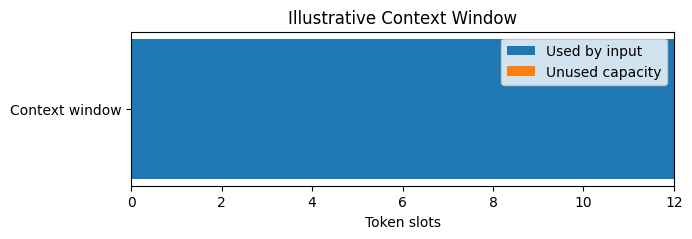

In [57]:

# STEP 4.1: Visualize context usage

total_tokens = len(tokens)
used_tokens = min(context_size, total_tokens)
remaining = max(0, context_size - used_tokens)

plt.figure(figsize=(7, 2))
plt.barh(
    ["Context window"],
    [used_tokens],
    label="Used by input"
)
plt.barh(
    ["Context window"],
    [remaining],
    left=[used_tokens],
    label="Unused capacity"
)

plt.xlim(0, context_size)
plt.xlabel("Token slots")
plt.title("Illustrative Context Window")
plt.legend()
plt.show()


Implement word embeddings

In [58]:

# STEP 5: Train Word2Vec embeddings

from gensim.models import Word2Vec

sentences = [
    ["machine", "learning", "uses", "data"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["neural", "networks", "learn", "patterns"],
    ["natural", "language", "processing", "analyzes", "text"],
    ["language", "models", "generate", "text"],
    ["machine", "learning", "models", "learn", "patterns"],
    ["word", "embeddings", "represent", "words", "as", "vectors"],
    ["deep", "learning", "models", "use", "data"]
]

model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    seed=42,
    epochs=100
)

word = "learning"

print("Embedding for:", word)
print(model.wv[word][:10])
print("Full vector size:", model.wv[word].shape)


Embedding for: learning
[-0.016  0.011  0.006 -0.002 -0.003  0.015 -0.017  0.008 -0.012 -0.016]
Full vector size: (50,)


In [59]:

# STEP 5.1: Calculate cosine similarity

word1 = "learning"
word2 = "models"

similarity = cosine_similarity(
    model.wv[word1].reshape(1, -1),
    model.wv[word2].reshape(1, -1)
)[0, 0]

print(f"Similarity between {word1} and {word2}: {similarity:.4f}")

print("\nMost similar words to 'learning':")
for word, score in model.wv.most_similar("learning", topn=5):
    print(word, round(score, 4))


Similarity between learning and models: -0.2117

Most similar words to 'learning':
represent 0.2494
uses 0.1437
generate 0.1239
natural 0.0971
networks 0.0537


Implement a Recurrent Neural Network (RNN)

In [60]:

# STEP 6: Prepare a small sentiment dataset

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

texts = [
    "I love this movie",
    "This film is excellent",
    "Amazing story and great acting",
    "I really enjoyed this",
    "The movie was wonderful",
    "I hate this movie",
    "This film is terrible",
    "Awful story and bad acting",
    "I really disliked this",
    "The movie was boring",
] * 30

labels = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0] * 30

X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

max_length = 8

X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_length, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_length, padding="post", truncating="post"
)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Training data shape:", X_train_pad.shape)
print("Test data shape:", X_test_pad.shape)
print("Vocabulary size:", len(tokenizer.word_index) + 1)


Training data shape: (240, 8)
Test data shape: (60, 8)
Vocabulary size: 25


In [61]:

# STEP 6.1: Build an RNN classifier

vocab_size = len(tokenizer.word_index) + 1

rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=16, mask_zero=True),
    SimpleRNN(16),
    Dense(1, activation="sigmoid")
])

rnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

history = rnn_model.fit(
    X_train_pad, y_train,
    epochs=8,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.6510 - loss: 0.6744 - val_accuracy: 0.7708 - val_loss: 0.6473
Epoch 2/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8750 - loss: 0.6201 - val_accuracy: 1.0000 - val_loss: 0.5889
Epoch 3/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.5529 - val_accuracy: 1.0000 - val_loss: 0.5111
Epoch 4/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.4645 - val_accuracy: 1.0000 - val_loss: 0.4130
Epoch 5/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.3585 - val_accuracy: 1.0000 - val_loss: 0.3139
Epoch 6/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.2633 - val_accuracy: 1.0000 - val_loss: 0.2291
Epoch 7/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.1873 - val_accuracy: 1.0000 - val_loss: 0.1677
Epoch 8/8
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.1360 - val_accuracy: 1.0000 - val_loss:

Test loss: 0.1131
Test accuracy: 1.0


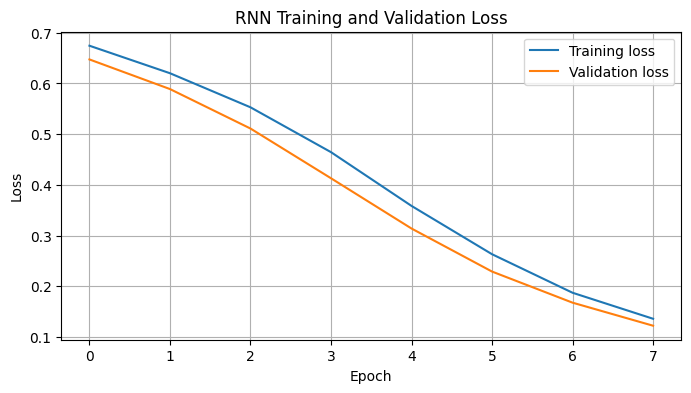

In [62]:

# STEP 6.2: Evaluate RNN

test_loss, test_accuracy = rnn_model.evaluate(
    X_test_pad, y_test, verbose=0
)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


Implement a Seq2Seq encoder-decoder model

In [63]:

# STEP 7: Prepare toy input-output sequences

import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Map digit strings to reversed digit strings.
# Example: "123" -> "321"

samples = [str(i).zfill(3) for i in range(100, 300)]
targets = [s[::-1] for s in samples]

characters = sorted(set("".join(samples + targets) + "\t\n"))
char_to_id = {char: i + 1 for i, char in enumerate(characters)}
id_to_char = {i: char for char, i in char_to_id.items()}

# 0 is reserved for padding.
vocab_size = len(char_to_id) + 1
seq_len = 3

encoder_input = np.zeros((len(samples), seq_len), dtype=np.int32)
decoder_input = np.zeros((len(samples), seq_len + 1), dtype=np.int32)
decoder_target = np.zeros((len(samples), seq_len + 1), dtype=np.int32)

for i, (source, target) in enumerate(zip(samples, targets)):
    encoder_input[i] = [char_to_id[c] for c in source]

    # Decoder input begins with a start token represented by tab.
    decoder_input[i] = [
        char_to_id["\t"]
    ] + [char_to_id[c] for c in target]

    # Decoder target ends with newline as the end token.
    decoder_target[i] = (
        [char_to_id[c] for c in target]
        + [char_to_id["\n"]]
    )

print("Encoder input shape:", encoder_input.shape)
print("Decoder input shape:", decoder_input.shape)
print("Decoder target shape:", decoder_target.shape)


Encoder input shape: (200, 3)
Decoder input shape: (200, 4)
Decoder target shape: (200, 4)


In [64]:

# STEP 7.1: Build Seq2Seq LSTM

latent_dim = 64

# Encoder
encoder_inputs = Input(shape=(seq_len,))
encoder_embedding = Embedding(vocab_size, 32, mask_zero=True)
encoder_embedded = encoder_embedding(encoder_inputs)

encoder_lstm = LSTM(latent_dim, return_state=True)
_, state_h, state_c = encoder_lstm(encoder_embedded)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(seq_len + 1,))
decoder_embedding = Embedding(vocab_size, 32, mask_zero=True)
decoder_embedded = decoder_embedding(decoder_inputs)

decoder_lstm = LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedded,
    initial_state=encoder_states
)

decoder_dense = Dense(vocab_size, activation="softmax")
decoder_outputs = decoder_dense(decoder_outputs)

seq2seq_model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

seq2seq_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

seq2seq_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 3, 32)     │        416 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 3)         │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 4, 32)     │        416 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 64),      │     24,832 │ embedding_2[0][0… │
│                     │ (None, 64),       │            │ not_equal_1[0][0] │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 4, 64),   │     24,832 │ embedding_3[0][0… │
│                     │ (None, 64),       │            │ lstm[0][1],       │
│                     │ (None, 64)]       │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 4, 13)     │        845 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 51,341 (200.55 KB)

 Trainable params: 51,341 (200.55 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:

# STEP 7.2: Train Seq2Seq

seq2seq_history = seq2seq_model.fit(
    [encoder_input, decoder_input],
    decoder_target[..., np.newaxis],
    batch_size=16,
    epochs=20,
    validation_split=0.2,
    verbose=1
)


Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.2797 - loss: 2.5419 - val_accuracy: 0.2750 - val_loss: 2.5254
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2937 - loss: 2.4554 - val_accuracy: 0.2750 - val_loss: 2.4243
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2766 - loss: 2.2038 - val_accuracy: 0.2750 - val_loss: 2.1480
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2828 - loss: 1.8957 - val_accuracy: 0.2750 - val_loss: 2.1097
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4453 - loss: 1.7691 - val_accuracy: 0.2750 - val_loss: 1.9721
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4109 - loss: 1.6575 - val_accuracy: 0.2750 - val_loss: 1.8486
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4609 - loss: 1.5563 - val_accuracy: 0.3000 - val_loss: 1.7934
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5047 - loss: 1.4604 - val_accuracy: 0.4062 - v

In [66]:

# STEP 7.3: Inspect Seq2Seq predictions

sample_index = 0

probabilities = seq2seq_model.predict(
    [
        encoder_input[sample_index:sample_index+1],
        decoder_input[sample_index:sample_index+1]
    ],
    verbose=0
)

predicted_ids = np.argmax(probabilities[0], axis=-1)

predicted_text = "".join(
    id_to_char.get(int(token_id), "")
    for token_id in predicted_ids
    if token_id != 0
)

print("Input:             ", samples[sample_index])
print("Expected output:   ", targets[sample_index])
print("Teacher-forced prediction:", predicted_text)


Input:              100
Expected output:    001
Teacher-forced prediction: 001

